# Incendios en el Perú, octubre de 2026 · 1. Datos, mapa base y cobertura

**Pregunta del proyecto:** ¿a quién alcanzan los incendios de octubre de 2026? Panorama nacional
con focos VIIRS y, a fondo, dos incendios en territorio de **comunidades campesinas quechuas del
Cusco**: **Livitaca** (Chumbivilcas) y **Huanoquite** (Paruro).

> Cómo se eligieron: primero se listaron los 107 incendios grandes del país (notebook 2) y se
> revisaron las nubes de Sentinel-2 en los candidatos. En la selva (Río Tambo, Pucallpa) las nubes
> tapaban entre 33 % y 99 % de la zona después del fuego; en el Cusco las imágenes estaban despejadas.

Este notebook prepara los datos y el contexto geográfico:

| Etapa | Qué hacemos |
|---|---|
| Descargar | Focos VIIRS (3 satélites), límites distritales, población, viviendas |
| Mapa base | Distritos, relieve sombreado (Copernicus DEM) y focos de la semana |
| Cobertura | ESA WorldCover: bosque, pastizal o cultivo |

In [1]:
import warnings
warnings.filterwarnings("ignore")

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import planetary_computer
import pystac_client
import requests

from comun import RAW, PROC, FIG, CORTE, STAC, leer_distritos, leer_focos

plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

## Descargar

Todo es público y sin clave. Cada archivo se baja una sola vez; si ya existe, se reutiliza.

| Dato | Fuente | Tipo |
|---|---|---|
| Focos de calor 7 días (S-NPP, NOAA-20, NOAA-21) | NASA FIRMS, CSV «South America 7d» | Puntos |
| Límites distritales con UBIGEO | GitHub `juaneladio/peru-geojson` (INEI) | Polígonos |
| Población 2020, 1 km | WorldPop, *unconstrained*, Perú | Raster |
| Edificaciones | Google Open Buildings v3, celda S2 `917` (sur del Cusco) | Puntos |
| Relieve y cobertura | Planetary Computer: `cop-dem-glo-30`, `esa-worldcover` | Raster (se leen en línea) |

In [2]:
FIRMS = "https://firms.modaps.eosdis.nasa.gov/data/active_fire"
DESCARGAS = {
    f"firms_viirs_snpp_sudamerica_7d_{CORTE}.csv": f"{FIRMS}/suomi-npp-viirs-c2/csv/SUOMI_VIIRS_C2_South_America_7d.csv",
    f"firms_viirs_noaa-20_sudamerica_7d_{CORTE}.csv": f"{FIRMS}/noaa-20-viirs-c2/csv/J1_VIIRS_C2_South_America_7d.csv",
    f"firms_viirs_noaa-21_sudamerica_7d_{CORTE}.csv": f"{FIRMS}/noaa-21-viirs-c2/csv/J2_VIIRS_C2_South_America_7d.csv",
    "peru_distrital_simple.geojson": "https://raw.githubusercontent.com/juaneladio/peru-geojson/master/peru_distrital_simple.geojson",
    "worldpop_per_2020_1km.tif": "https://data.worldpop.org/GIS/Population/Global_2000_2020_1km/2020/PER/per_ppp_2020_1km_Aggregated.tif",
    "open_buildings_v3_points_917.csv.gz": "https://storage.googleapis.com/open-buildings-data/v3/points_s2_level_4_gzip/917_buildings.csv.gz",
}

for nombre, url in DESCARGAS.items():
    destino = RAW / nombre
    if not destino.exists():
        with requests.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(destino, "wb") as fh:
                for trozo in r.iter_content(1 << 20):
                    fh.write(trozo)
    print(f"{destino.stat().st_size / 1e6:8.1f} MB  {nombre}")

     4.9 MB  firms_viirs_snpp_sudamerica_7d_2026-10-21.csv
     5.2 MB  firms_viirs_noaa-20_sudamerica_7d_2026-10-21.csv
     5.0 MB  firms_viirs_noaa-21_sudamerica_7d_2026-10-21.csv
     1.9 MB  peru_distrital_simple.geojson
     7.4 MB  worldpop_per_2020_1km.tif
    92.8 MB  open_buildings_v3_points_917.csv.gz


## Mapa base

1 834 distritos con su UBIGEO (versión simplificada: los bordes son aproximados). Ubicamos los dos distritos de estudio y definimos la región del mapa:
la caja que los contiene, con un margen de ~15 km.

In [3]:
distritos = leer_distritos()
estudio = distritos[distritos.NOMBDIST.isin(["LIVITACA", "HUANOQUITE"])]
for _, d in estudio.iterrows():
    km2 = gpd.GeoSeries([d.geometry], crs=4326).to_crs(32718).area.iloc[0] / 1e6
    print(f"{d.NOMBDIST.title():11s} UBIGEO {d.IDDIST} · {d.NOMBPROV.title()}, {d.NOMBDEP.title()} · {km2:,.0f} km²")
x0, y0, x1, y1 = estudio.total_bounds
caja = (x0 - 0.15, y0 - 0.15, x1 + 0.15, y1 + 0.15)

Livitaca    UBIGEO 080705 · Chumbivilcas, Cusco · 750 km²
Huanoquite  UBIGEO 081005 · Paruro, Cusco · 352 km²


**Relieve.** Viene del modelo Copernicus DEM (30 m). Lo leemos solo en la caja y a resolución
reducida (vista general del COG, ~120 m): para un mapa regional basta.

Para que el relieve **se vea**, calculamos un **sombreado** (*hillshade*): se simula una luz que
viene del noroeste (azimut 315°, 45° de altura) y cada ladera se aclara u oscurece según cuánto mira
hacia esa luz. El color indica la altitud; la sombra, la forma del terreno (quebradas, cumbres).
Como el DEM está en grados, convertimos el tamaño del píxel a metros antes de calcular pendientes.

In [4]:
import rioxarray
from rioxarray.merge import merge_arrays
from matplotlib.colors import LightSource

catalogo = pystac_client.Client.open(STAC, modifier=planetary_computer.sign_inplace)


def mosaico(coleccion, activo, nivel, caja=caja):
    """Lee y une las teselas de una colección de Planetary Computer recortadas a la caja."""
    items = catalogo.search(collections=[coleccion], bbox=list(caja)).item_collection()
    piezas = [rioxarray.open_rasterio(it.assets[activo].href, overview_level=nivel)
              .rio.clip_box(*caja) for it in items]
    return merge_arrays(piezas).squeeze()


dem = mosaico("cop-dem-glo-30", "data", nivel=1)          # ~120 m por píxel
dem = dem.where(dem > -100)
lat_media = (caja[1] + caja[3]) / 2
dx = abs(float(dem.x[1] - dem.x[0])) * 111_320 * np.cos(np.radians(lat_media))
dy = abs(float(dem.y[1] - dem.y[0])) * 110_574
print(f"DEM: {dem.shape} · píxel ≈ {dx:.0f} × {dy:.0f} m · altitud {float(dem.min()):,.0f}–{float(dem.max()):,.0f} m")

luz = LightSource(azdeg=315, altdeg=45)
z = dem.fillna(float(dem.min())).values
relieve = luz.shade(z, cmap=plt.cm.terrain, blend_mode="soft", vert_exag=1.5, dx=dx, dy=dy,
                    vmin=1500, vmax=5200)
ext_dem = [float(dem.x.min()), float(dem.x.max()), float(dem.y.min()), float(dem.y.max())]

DEM: (1140, 913) · píxel ≈ 120 × 123 m · altitud 0–5,069 m


Sobre el relieve ponemos los **focos VIIRS de la semana** (sin limpiar todavía: la limpieza se
hace en el notebook 2) para ver dónde está el fuego en la región.

focos (confianza nominal o alta) en la región: 294


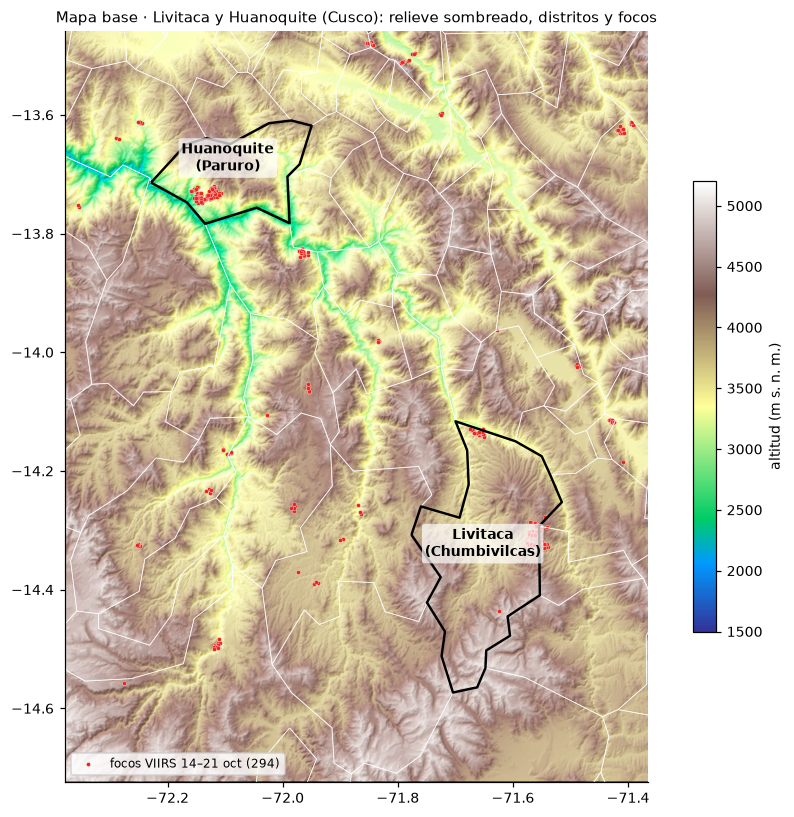

In [5]:
focos = leer_focos()
focos = focos[(focos.confidence != "low") & focos.longitude.between(caja[0], caja[2]) & focos.latitude.between(caja[1], caja[3])]
print(f"focos (confianza nominal o alta) en la región: {len(focos):,}")

fig, ax = plt.subplots(figsize=(8.5, 7.5))
ax.imshow(relieve, extent=ext_dem)
distritos.boundary.plot(ax=ax, color="white", linewidth=0.5, alpha=0.8)
estudio.boundary.plot(ax=ax, color="black", linewidth=1.6)
ax.scatter(focos.longitude, focos.latitude, s=7, c="#e8261c", edgecolors="white", linewidths=0.2,
           label=f"focos VIIRS 14–21 oct ({len(focos):,})")
for _, d in estudio.iterrows():
    c = d.geometry.representative_point()
    ax.annotate(f"{d.NOMBDIST.title()}\n({d.NOMBPROV.title()})", (c.x, c.y), fontsize=9, fontweight="bold",
                ha="center", color="black", bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7, lw=0))
ax.set_xlim(caja[0], caja[2]); ax.set_ylim(caja[1], caja[3])
sm = plt.cm.ScalarMappable(cmap="terrain", norm=plt.Normalize(1500, 5200))
plt.colorbar(sm, ax=ax, shrink=0.6, label="altitud (m s. n. m.)")
ax.legend(loc="lower left", fontsize=8)
ax.set_title("Mapa base · Livitaca y Huanoquite (Cusco): relieve sombreado, distritos y focos", fontsize=10)
plt.tight_layout(); fig.savefig(FIG / "01_mapa_base_cusco.png", dpi=150); plt.show()

Los dos distritos están en la sierra sur del Cusco, entre los ríos Apurímac y Velille. Huanoquite
baja en quebradas profundas hacia el Apurímac; Livitaca es más alto, con mesetas de puna por encima
de los 4 000 m. Es territorio de comunidades campesinas que combinan agricultura en los valles con
ganadería (vacunos, ovinos, camélidos) en los pastos de altura, donde ocurrieron los incendios.

## Cobertura del suelo

ESA WorldCover 2021 (10 m). En el mapa regional usamos una vista general (~80 m); el cruce fino
con el área quemada se hace a 20 m en el notebook 3.

In [6]:
CLASES_WC = {10: "Bosque", 20: "Matorral", 30: "Pastizal", 40: "Cultivo", 50: "Urbano",
             60: "Suelo desnudo", 70: "Nieve", 80: "Agua", 90: "Humedal", 95: "Manglar", 100: "Musgo"}

wc = mosaico("esa-worldcover", "map", nivel=2)
dist_wc = (pd.Series(wc.values.ravel()).value_counts(normalize=True)
           .rename(index=CLASES_WC).drop(index=0, errors="ignore"))
print("Cobertura en la región de Livitaca y Huanoquite (%):")
print((dist_wc * 100).round(1).head(6).to_string())

Cobertura en la región de Livitaca y Huanoquite (%):
Pastizal         89.2
Cultivo           3.9
Bosque            3.5
Suelo desnudo     1.9
Urbano            0.6
Agua              0.4


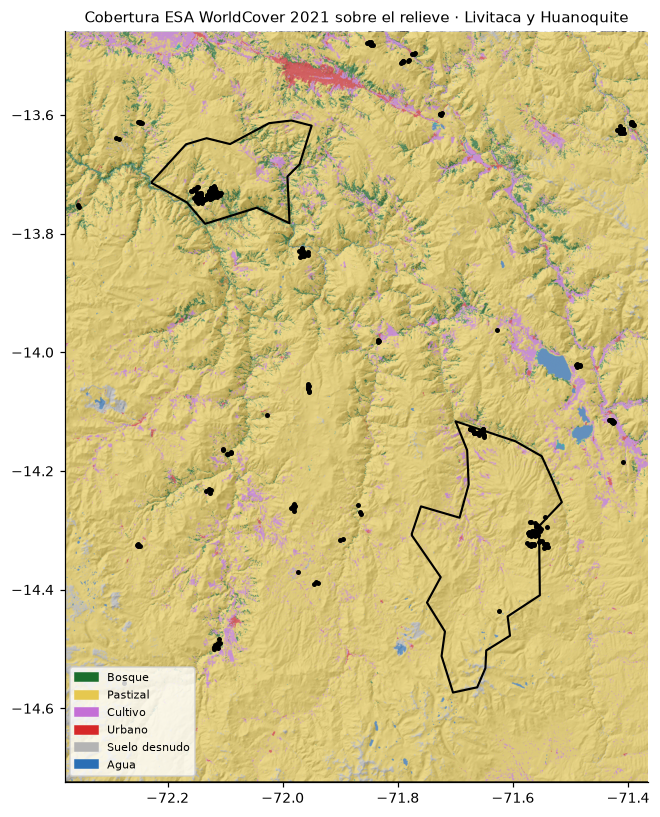

In [7]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
colores = ["#1b6e2d", "#c98a2b", "#e6c84f", "#c46fd6", "#d62728", "#b4b4b4",
           "#f0f0f0", "#2a6fb5", "#0096a0", "#00cf75", "#fae6a0"]
codigos = list(CLASES_WC)
cmap = ListedColormap(colores); norm = BoundaryNorm(codigos + [101], cmap.N)

fig, ax = plt.subplots(figsize=(8.5, 7.5))
ax.imshow(luz.hillshade(z, vert_exag=1.5, dx=dx, dy=dy), cmap="gray", extent=ext_dem)   # relieve debajo
ax.imshow(wc.where(wc > 0).values, cmap=cmap, norm=norm, alpha=0.65,
          extent=[float(wc.x.min()), float(wc.x.max()), float(wc.y.min()), float(wc.y.max())])
estudio.boundary.plot(ax=ax, color="black", linewidth=1.4)
ax.scatter(focos.longitude, focos.latitude, s=5, c="black", label="focos VIIRS")
ax.legend(handles=[Patch(color=c, label=CLASES_WC[k]) for k, c in zip(codigos, colores)
                   if CLASES_WC[k] in dist_wc.index[:6]], loc="lower left", fontsize=7.5, frameon=True)
ax.set_xlim(caja[0], caja[2]); ax.set_ylim(caja[1], caja[3])
ax.set_title("Cobertura ESA WorldCover 2021 sobre el relieve · Livitaca y Huanoquite", fontsize=10)
plt.tight_layout(); fig.savefig(FIG / "01_cobertura_cusco.png", dpi=150); plt.show()

El pastizal domina la región: es la cobertura de la puna y de las laderas altas. El bosque se limita a
las quebradas. Por eso, cuando el fuego se escapa de una quema de pastos, lo que arde es pastizal
(notebook 3).